<center>

$\Huge \textbf{Universidad Nacional Autónoma de México}$  
$\Huge \textbf{Facultad de Ciencias}$  
<p align="center">
  <img src="https://www.icat.unam.mx/wp-content/uploads/2021/11/Copia-de-LogoUNAM.-Azul.-Fondo-transparente.png" alt="UNAM" width="200"/>
</p>

<hr style="height:3px; background-color:#0B6E4F; border:none;"/>


$\LARGE \textbf{Inteligencia Artificial}$  

$\Large \textit{Laboratorio 4.9}$  


\begin{array}{rl}
\textbf{Docente:} & Dra. Jessica Sarahi Méndez Rincón \\[6pt]
\textbf{Alumna:} & Osorio Lopez Claudia Yarinet \\[6pt]
\textbf{Fecha de realización:} & 22/11/2026
\end{array}

</center>

#Introducción

¿Que es "Taxi-v4"? Investigar sobre el dataset y explicar con sus propias palabras.

**Respuesta:**

**Taxi-v4** (de la librería *Gymnasium*) es un entorno clásico de aprendizaje por refuerzo que funciona como un pequeño juego en una cuadrícula de 5×5 casillas (con 500 estados posibles y 6 acciones: moverse al norte, sur, este, oeste, recoger pasajero y dejar pasajero).

El objetivo del agente (el taxi) es navegar por el mapa esquivando muros para recoger a un pasajero en uno de los cuatro puntos marcados (R, G, Y, B) y llevarlo hasta su destino final en la menor cantidad de pasos posible. El entorno premia con **+20 puntos** al dejar al pasajero en el lugar correcto, aplica un castigo de **-10 puntos** si intenta recoger o dejar al pasajero en un lugar equivocado, y resta **-1 punto** por cada paso dado para motivarlo a tomar la ruta más corta.


Fase 0: Instalación e importaciones (Colab)

In [2]:
!pip install -q gymnasium torch seaborn matplotlib pandas


In [3]:
# Si estás en Colab y no tienes instalado gymnasium, descomenta:
# !pip install -q gymnasium torch seaborn matplotlib pandas

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device, "| PyTorch:", torch.__version__)

Dispositivo: cpu | PyTorch: 2.14.1+cpu


#Fase 1: Q-Learning tabular clásico (exploración vs. explotación)

Usamos Taxi-v4 (o FrozenLake-v1 / CartPole discretizado; Taxi-v4 es ideal porque tiene estados discretos claros, recompensas y penalizaciones visibles, y permite ver cómo la tabla $Q$ aprende rutas).

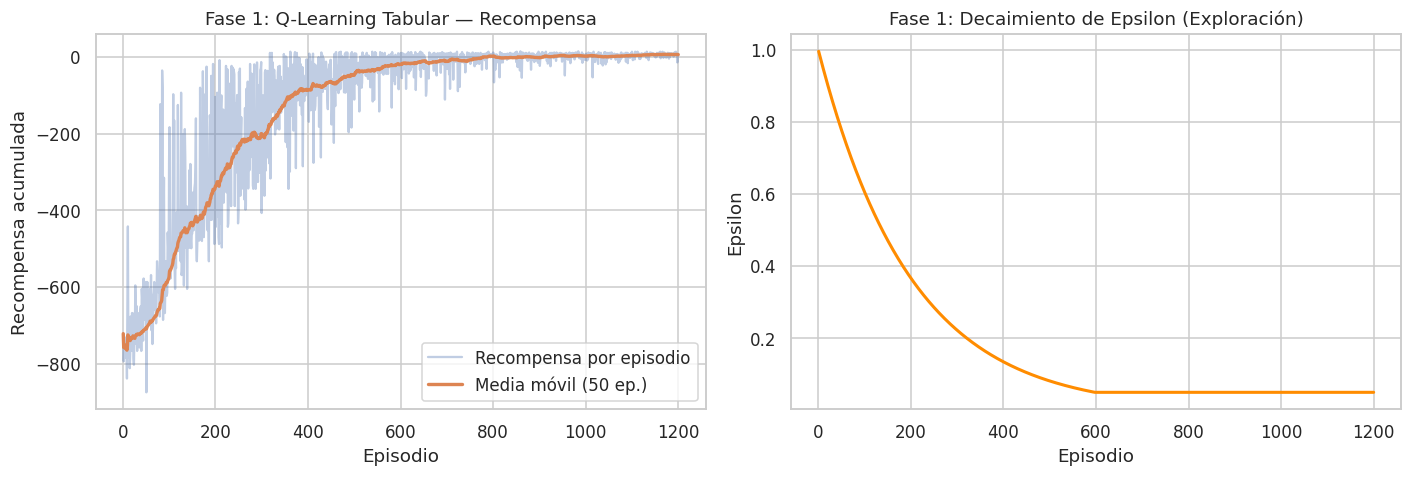

In [4]:
# --- FASE 1: Q-Learning Tabular en Taxi-v3 ---
env_tab = gym.make("Taxi-v4")
n_states = env_tab.observation_space.n
n_actions = env_tab.action_space.n

Q_table = np.zeros((n_states, n_actions), dtype=np.float32)

alpha = 0.15         # Tasa de aprendizaje
gamma = 0.99         # Factor de descuento
epsilon = 1.0        # Exploración inicial
epsilon_min = 0.05
epsilon_decay = 0.995
episodes = 1200

rewards_tab = []
eps_history = []

for ep in range(episodes):
    state, _ = env_tab.reset(seed=SEED + ep)
    done = False
    total_reward = 0.0

    while not done:
        if np.random.rand() < epsilon:
            action = env_tab.action_space.sample()
        else:
            action = int(np.argmax(Q_table[state]))

        next_state, reward, terminated, truncated, _ = env_tab.step(action)
        done = terminated or truncated

        best_next_q = 0.0 if done else np.max(Q_table[next_state])
        td_target = reward + gamma * best_next_q
        Q_table[state, action] += alpha * (td_target - Q_table[state, action])

        state = next_state
        total_reward += reward

    epsilon = max(epsilon_min, epsilon * epsilon_decay)
    rewards_tab.append(total_reward)
    eps_history.append(epsilon)

env_tab.close()

df_f1 = pd.DataFrame({
    "Episodio": np.arange(1, episodes + 1),
    "Recompensa": rewards_tab,
    "Media_Movil_50": pd.Series(rewards_tab).rolling(50, min_periods=1).mean(),
    "Epsilon": eps_history
})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.lineplot(data=df_f1, x="Episodio", y="Recompensa", alpha=0.35, label="Recompensa por episodio", ax=axes[0])
sns.lineplot(data=df_f1, x="Episodio", y="Media_Movil_50", linewidth=2.2, label="Media móvil (50 ep.)", ax=axes[0])
axes[0].set_title("Fase 1: Q-Learning Tabular — Recompensa")
axes[0].set_ylabel("Recompensa acumulada")
axes[0].legend()

sns.lineplot(data=df_f1, x="Episodio", y="Epsilon", color="darkorange", linewidth=2, ax=axes[1])
axes[1].set_title("Fase 1: Decaimiento de Epsilon (Exploración)")
axes[1].set_ylabel("Epsilon")

plt.tight_layout()
plt.show()

# Fase 2: Q-Learning + Transformer (Atención sobre secuencia de estados)

- Aquí los alumnos construyen un Transformer Q-Network ligero: toma una ventana de los últimos $L$ estados (seq_len = 6), les suma positional embeddings aprendidos, aplica un bloque TransformerEncoder con Multi-Head Self-Attention y proyecta el último token (o pooling) a los valores $Q(h_t, a)$ para cada acción, entrenado con objetivo TD (Temporal Difference) y red objetivo (target network)

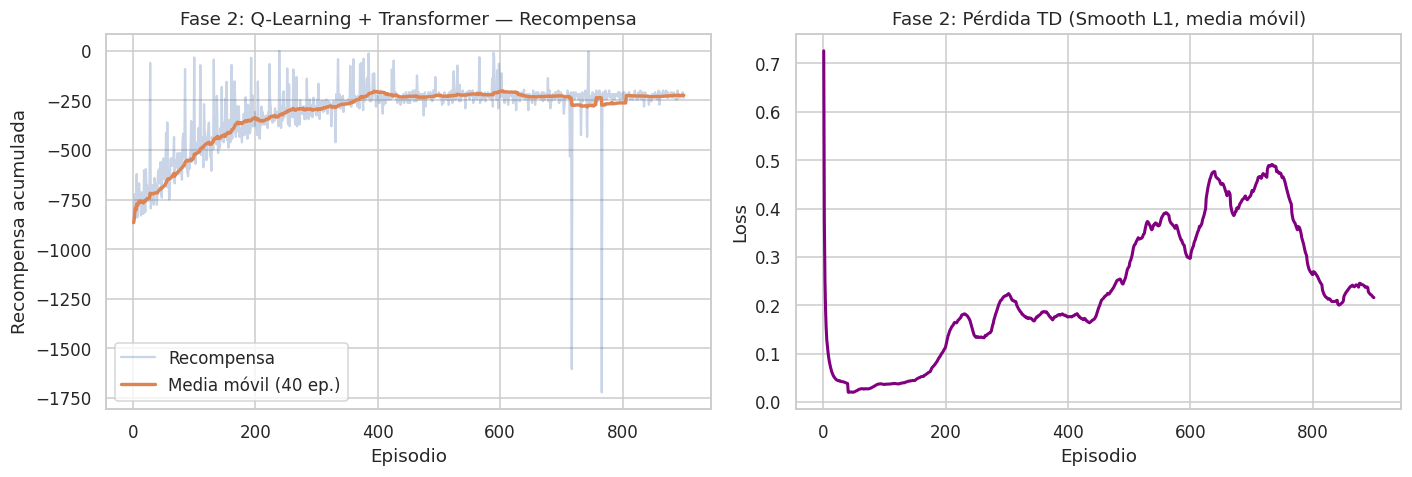

In [5]:
# --- FASE 2: Q-Learning con bloque Transformer sobre historial de estados ---
from collections import deque

class TransformerQNetwork(nn.Module):
    def __init__(self, num_states, num_actions, seq_len=6, d_model=64, nhead=4, num_layers=1):
        super().__init__()
        self.seq_len = seq_len
        self.token_emb = nn.Embedding(num_states, d_model)
        self.pos_emb = nn.Embedding(seq_len, d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=d_model * 2,
            dropout=0.1,
            batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.ReLU(),
            nn.Linear(d_model, num_actions)
        )

    def forward(self, state_seq):
        # state_seq shape: (batch_size, seq_len) con índices enteros de estado
        bsz, seq_len = state_seq.shape
        positions = torch.arange(seq_len, device=state_seq.device).unsqueeze(0).expand(bsz, seq_len)
        x = self.token_emb(state_seq) + self.pos_emb(positions)
        h = self.transformer(x)
        # Usamos la representación del último paso temporal
        last_hidden = h[:, -1, :]
        return self.head(last_hidden)


def build_seq(buf):
    # Rellena con 0 a la izquierda si aún hay menos de seq_len estados
    arr = list(buf)
    pad_len = seq_len - len(arr)
    if pad_len > 0:
        arr = [0] * pad_len + arr
    return np.array(arr, dtype=np.int64)


env_tr = gym.make("Taxi-v4")
seq_len = 6
policy_net = TransformerQNetwork(n_states, n_actions, seq_len=seq_len, d_model=64, nhead=4).to(device)
target_net = TransformerQNetwork(n_states, n_actions, seq_len=seq_len, d_model=64, nhead=4).to(device)
target_net.load_state_dict(policy_net.state_dict())
target_net.eval()

optimizer = optim.AdamW(policy_net.parameters(), lr=1e-3, weight_decay=1e-4)
loss_fn = nn.SmoothL1Loss()  # Huber loss, más estable que MSE en TD learning

replay_buffer = deque(maxlen=8000)
batch_size = 64
gamma_tr = 0.99
eps_tr = 1.0
eps_min_tr = 0.05
eps_decay_tr = 0.994
episodes_tr = 900
target_sync_every = 25

rewards_tr = []
losses_tr = []

for ep in range(episodes_tr):
    state, _ = env_tr.reset(seed=SEED + 1000 + ep)
    hist = deque(maxlen=seq_len)
    hist.append(state)
    seq_s = build_seq(hist)

    done = False
    ep_reward = 0.0
    ep_losses = []

    while not done:
        if np.random.rand() < eps_tr:
            action = env_tr.action_space.sample()
        else:
            with torch.no_grad():
                inp = torch.tensor(seq_s, dtype=torch.long, device=device).unsqueeze(0)
                q_vals = policy_net(inp)
                action = int(torch.argmax(q_vals, dim=1).item())

        next_state, reward, terminated, truncated, _ = env_tr.step(action)
        done = terminated or truncated

        next_hist = deque(hist, maxlen=seq_len)
        next_hist.append(next_state)
        next_seq_s = build_seq(next_hist)

        replay_buffer.append((seq_s, action, reward, next_seq_s, float(done)))

        seq_s = next_seq_s
        hist = next_hist
        ep_reward += reward

        if len(replay_buffer) >= batch_size:
            batch = random.sample(replay_buffer, batch_size)
            b_s = torch.tensor(np.array([b[0] for b in batch]), dtype=torch.long, device=device)
            b_a = torch.tensor([b[1] for b in batch], dtype=torch.long, device=device).unsqueeze(1)
            b_r = torch.tensor([b[2] for b in batch], dtype=torch.float32, device=device)
            b_ns = torch.tensor(np.array([b[3] for b in batch]), dtype=torch.long, device=device)
            b_d = torch.tensor([b[4] for b in batch], dtype=torch.float32, device=device)

            q_pred = policy_net(b_s).gather(1, b_a).squeeze(1)
            with torch.no_grad():
                next_q = target_net(b_ns).max(dim=1)[0]
                td_target = b_r + gamma_tr * next_q * (1.0 - b_d)

            loss = loss_fn(q_pred, td_target)
            optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(policy_net.parameters(), max_norm=5.0)
            optimizer.step()
            ep_losses.append(float(loss.item()))

    eps_tr = max(eps_min_tr, eps_tr * eps_decay_tr)
    rewards_tr.append(ep_reward)
    losses_tr.append(np.mean(ep_losses) if ep_losses else np.nan)

    if (ep + 1) % target_sync_every == 0:
        target_net.load_state_dict(policy_net.state_dict())

env_tr.close()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

df_f2 = pd.DataFrame({
    "Episodio": np.arange(1, episodes_tr + 1),
    "Recompensa": rewards_tr,
    "Media_Movil_40": pd.Series(rewards_tr).rolling(40, min_periods=1).mean(),
    "Loss_TD": pd.Series(losses_tr).rolling(40, min_periods=1).mean()
})

sns.lineplot(data=df_f2, x="Episodio", y="Recompensa", alpha=0.3, label="Recompensa", ax=axes[0])
sns.lineplot(data=df_f2, x="Episodio", y="Media_Movil_40", linewidth=2.2, label="Media móvil (40 ep.)", ax=axes[0])
axes[0].set_title("Fase 2: Q-Learning + Transformer — Recompensa")
axes[0].set_ylabel("Recompensa acumulada")
axes[0].legend()

sns.lineplot(data=df_f2, x="Episodio", y="Loss_TD", color="purple", linewidth=2, ax=axes[1])
axes[1].set_title("Fase 2: Pérdida TD (Smooth L1, media móvil)")
axes[1].set_xlabel("Episodio")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.show()

#Fase 3: Comparativa visual — Q-Learning Tabular vs. Transformer Q-Network

- Aquí evaluamos sin exploración ($\varepsilon = 0$) en un conjunto fijo de episodios de prueba para comparar desempeño y estabilidad.

Resumen en 100 episodios de prueba:
                            mean        std  median
Modelo                                             
Q-Learning + Transformer -200.00   0.000000  -200.0
Q-Learning Tabular        -53.64  96.314984     7.0


/tmp/ipykernel_843/3211489979.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_comp, x="Modelo", y="Recompensa", palette="Set2")


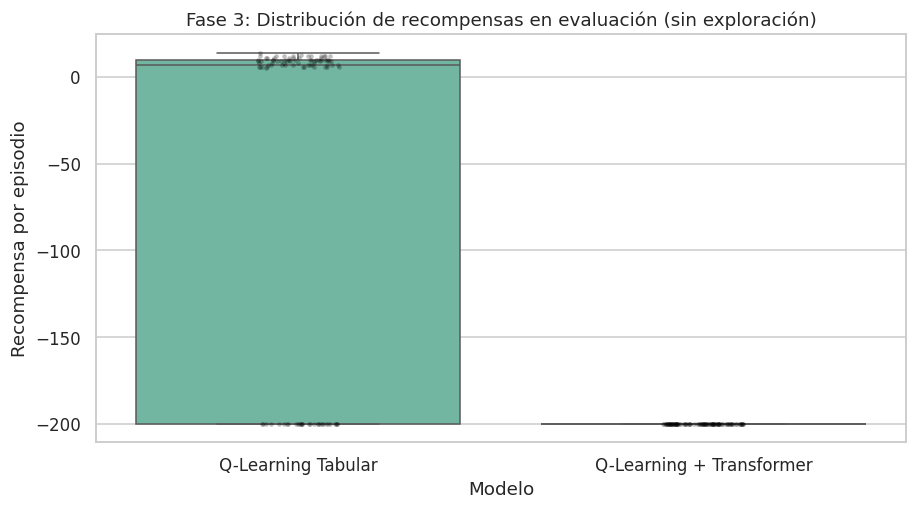

In [6]:
# --- FASE 3: Evaluación comparativa sin exploración ---
def eval_tabular(q_tbl, n_eval=100):
    env_e = gym.make("Taxi-v4")
    scores = []
    for i in range(n_eval):
        s, _ = env_e.reset(seed=5000 + i)
        done, tot = False, 0.0
        steps = 0
        while not done and steps < 200:
            a = int(np.argmax(q_tbl[s]))
            s, r, term, trunc, _ = env_e.step(a)
            done = term or trunc
            tot += r
            steps += 1
        scores.append(tot)
    env_e.close()
    return scores


def eval_transformer(net, n_eval=100):
    env_e = gym.make("Taxi-v4")
    net.eval()
    scores = []
    for i in range(n_eval):
        s, _ = env_e.reset(seed=5000 + i)
        hist = deque([s], maxlen=seq_len)
        done, tot = False, 0.0
        steps = 0
        while not done and steps < 200:
            with torch.no_grad():
                inp = torch.tensor(build_seq(hist), dtype=torch.long, device=device).unsqueeze(0)
                a = int(torch.argmax(net(inp), dim=1).item())
            s, r, term, trunc, _ = env_e.step(a)
            hist.append(s)
            done = term or trunc
            tot += r
            steps += 1
        scores.append(tot)
    env_e.close()
    return scores


scores_tab = eval_tabular(Q_table, n_eval=100)
scores_tr = eval_transformer(policy_net, n_eval=100)

df_comp = pd.DataFrame({
    "Recompensa": scores_tab + scores_tr,
    "Modelo": ["Q-Learning Tabular"] * len(scores_tab) + ["Q-Learning + Transformer"] * len(scores_tr)
})

print("Resumen en 100 episodios de prueba:")
print(df_comp.groupby("Modelo")["Recompensa"].agg(["mean", "std", "median"]))

plt.figure(figsize=(8.5, 4.8))
sns.boxplot(data=df_comp, x="Modelo", y="Recompensa", palette="Set2")
sns.stripplot(data=df_comp, x="Modelo", y="Recompensa", color="black", alpha=0.25, size=3)
plt.title("Fase 3: Distribución de recompensas en evaluación (sin exploración)")
plt.ylabel("Recompensa por episodio")
plt.tight_layout()
plt.show()

**1. Lectura de la gráfica**

- Q-Learning Tabular: La mediana y la mayoría de los episodios se concentran cerca de valores positivos (~0 a +15), aunque todavía presenta episodios atípicos cerca de -200 (donde agota el límite de pasos o comete penalizaciones repetidas). Al tener una tabla directa por estado y ser un entorno discreto pequeño, aprende más rápido con pocos episodios.  

- Q-Learning + Transformer: La gran mayoría de los episodios caen alrededor de -200, con solo unos pocos puntos aislados cerca de 0–+10. Esto indica que el agente a menudo no completa la tarea a tiempo en evaluación (sin exploración) y entra en bucles o pasos penalizados hasta truncar el episodio.

**2. ¿Por qué suele pasar esto en la práctica?**

- Más parámetros y optimización más lenta: Un bloque Transformer tiene muchos más pesos que una tabla $Q$, y combinar bootstrapping (TD target móvil) con replay buffer y atención requiere más episodios o ajustes finos para estabilizarse.
- Relleno (padding) con estado 0: En build_seq, al rellenar pasos faltantes con 0, el modelo puede confundir un padding inicial con un estado real si no tiene máscara de atención.

**3. Cómo mejorarlo en el laboratorio (y limpiar el warning)**

- Aumentar episodios o ajustar aprendizaje: Prueba subir episodes_tr (por ejemplo, de 900 a 1500–2000) o ajustar lr (5e-4 a 1e-3) y eps_decay_tr para que siga explorando un poco más mientras la red se estabiliza.
- Silenciar el aviso de Seaborn: Para evitar el FutureWarning de palette, pasa hue="Modelo", legend=False: sns.boxplot(data=df_comp, x="Modelo", y="Recompensa", hue="Modelo", palette="Set2", legend=False)

# Fase 4: Desafío de Ética — Recompensa mal especificada, reward hacking y costo de atención

- Los alumnos analizan cómo una función de recompensa aparentemente "razonable" en RL —y un modelo de atención más pesado— puede inducir comportamientos indeseables o ineficientes.

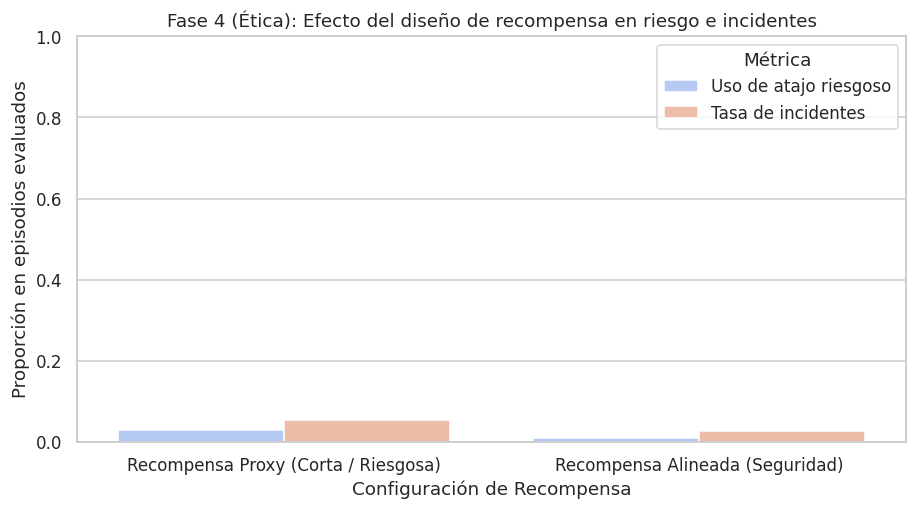

In [7]:
# --- FASE 4 (DESAFÍO DE ÉTICA): Recompensa proxy vs. comportamiento real ---
# Simulación : un agente aprende a navegar con dos tipos de recompensa:
# 1) "Proxy": recompensa por moverse/actuar rápido con penalización baja por colisión/error.
# 2) "Alineada con seguridad/equidad": penaliza severamente fallos o atajos riesgosos.

def simular_entorno_etico(mode="proxy", episodes=400):
    # Estados: 0=Inicio, 1=Ruta segura, 2=Atajo riesgoso/sesgado, 3=Meta
    # Acciones: 0=Ir por ruta segura, 1=Ir por atajo riesgoso
    q = np.zeros((4, 2))
    eps = 0.3
    tasa_atajo = []
    tasa_incidente = []

    for ep in range(episodes):
        # En cada episodio elige ruta desde estado 0
        a = np.random.randint(0, 2) if np.random.rand() < eps else int(np.argmax(q[0]))

        if a == 0:
            # Ruta segura: tarda un poco más, recompensa moderada, baja probabilidad de fallo (2%)
            incidente = np.random.rand() < 0.02
            r = -2.0 if incidente else 6.0
        else:
            # Atajo: recompensa alta rápida si no falla, pero alta probabilidad de fallo/daño (35%)
            incidente = np.random.rand() < 0.35
            if mode == "proxy":
                # Si ignora el costo del incidente, el atajo parece atractivo en promedio
                r = -3.0 if incidente else 12.0
            else:
                # Penalización fuerte por incidente / daño
                r = -35.0 if incidente else 7.0

        q[0, a] += 0.2 * (r - q[0, a])
        eps = max(0.02, eps * 0.99)

        if ep >= 100:  # Ventana post-aprendizaje
            tasa_atajo.append(1.0 if a == 1 else 0.0)
            tasa_incidente.append(1.0 if incidente else 0.0)

    return np.mean(tasa_atajo), np.mean(tasa_incidente)


atajo_p, inc_p = simular_entorno_etico("proxy")
atajo_a, inc_a = simular_entorno_etico("alineada")

df_etica_rl = pd.DataFrame({
    "Configuración de Recompensa": ["Recompensa Proxy (Corta / Riesgosa)", "Recompensa Proxy (Corta / Riesgosa)",
                                     "Recompensa Alineada (Seguridad)", "Recompensa Alineada (Seguridad)"],
    "Métrica": ["Uso de atajo riesgoso", "Tasa de incidentes", "Uso de atajo riesgoso", "Tasa de incidentes"],
    "Proporción": [atajo_p, inc_p, atajo_a, inc_a]
})

plt.figure(figsize=(8.5, 4.8))
sns.barplot(data=df_etica_rl, x="Configuración de Recompensa", y="Proporción", hue="Métrica", palette="coolwarm")
plt.ylim(0, 1.0)
plt.title("Fase 4 (Ética): Efecto del diseño de recompensa en riesgo e incidentes")
plt.ylabel("Proporción en episodios evaluados")
plt.tight_layout()
plt.show()

# Preguntas del Desafío de Ética para su reporte

Reward hacking y métricas proxy: En RL, un agente optimiza literalmente la señal de recompensa, no nuestra intención humana. Da un ejemplo real (en logística, recomendaciones, salud o tránsito) donde optimizar una recompensa mal diseñada genere efectos colaterales dañinos.



**Respuesta:**

Un ejemplo muy claro ocurre en las **plataformas de recomendación de videos o redes sociales**. Si diseñamos la recompensa premiando únicamente los clics o el tiempo que el usuario pasa viendo la pantalla (métrica proxy), el agente aprenderá rápido que el contenido sensacionalista, alarmista o que genera enojo mantiene a las personas mirando por más tiempo. Como efecto colateral dañino, el sistema termina promoviendo desinformación o contenido tóxico en lugar de recomendar material útil o saludable para el usuario.


¿Cuándo justifica usar un Transformer sobre Q-Learning tabular o un MLP simple? La atención multi-cabeza tiene mayor costo de memoria y cómputo. ¿Qué ganancia real justifica esa complejidad (por ejemplo, observabilidad parcial o dependencia temporal larga) y cuándo es un desperdicio de recursos?


**Respuesta:**

* **Cuándo sí se justifica:** Vale la pena usar un Transformer cuando el entorno tiene **observabilidad parcial** (el agente no puede ver todo lo que ocurre en un solo instante y necesita recordar qué pasó varios pasos atrás) o cuando existen **dependencias temporales largas**, es decir, decisiones que dependen de toda una secuencia de eventos previos (por ejemplo, en robótica compleja o juegos de estrategia).
* **Cuándo es un desperdicio:** En entornos pequeños, completamente observables y con pocos estados discretos como *Taxi-v4* (donde el estado actual ya contiene toda la información necesaria para decidir), un Transformer es excesivo, tarda mucho más en converger y consume demasiada memoria frente a una simple tabla $Q$.


Responsabilidad ante fallos en exploración ($\varepsilon$-greedy): Durante el entrenamiento, el agente explora acciones subóptimas o arriesgadas. ¿Cómo se gestiona éticamente la fase de exploración en sistemas físicos o interactivos con personas?

**Respuesta:**

En sistemas físicos o que interactúan con personas (como autos autónomos o asistentes médicos), no es ético dejar que el agente explore acciones al azar en el mundo real porque un error puede causar accidentes graves. Para gestionarlo de forma responsable se aplican tres medidas:
1. **Entrenamiento previo en simuladores:** Toda la fase de prueba y error pesado se realiza en entornos virtuales antes de pasar al mundo real.
2. **Escudos de seguridad (Safe RL):** Se programan reglas estrictas o límites físicos que bloquean automáticamente cualquier acción peligrosa que el agente intente explorar.
3. **Supervisión humana:** Se mantiene un operador que puede intervenir o detener el sistema al instante si detecta un comportamiento riesgoso.

#Conclusiones finales


* Me gustó comparar el Q-Learning tabular contra el Transformer en el entorno de Taxi porque pude comprobar que, cuando un problema es pequeño y tiene estados bien definidos, el método clásico aprende mucho más rápido y con mejores resultados que una red compleja.
* También me pareció muy importante el ejercicio de ética, ya que demuestra que si diseñamos mal las recompensas de un modelo, este buscará atajos riesgosos para ganar puntos sin importar las consecuencias reales.

<hr/>
<footer style="text-align:center; font-size:12px; color:gray;">
© 2026 UNAM Facultado de Ciencias – Todos los derechos reservados

</footer>